# Telco Customer Churn — Analysis, Models and Recommendations

**Audience:** retention team (product / analytics).
**Question:** which customers are likely to cancel next month, and why, so the team can intervene before they leave?

**Data:** IBM Telco Customer Churn sample — 7,043 customers, 21 columns (demographics, services, account and billing details, and whether the customer churned in the last month). Licensed CC BY 4.0.

**How to read this notebook.** Every number below is computed in the cell above it from the code in `churn_pipeline/`. The notebook calls the same functions the API and CLI use, so the analysis and the served model behave identically.

Contents: 1. Data load (simulated warehouse) · 2. Cleaning · 3. Exploratory analysis · 4. Leakage review · 5. Baseline decision tree · 6. Feature engineering + logistic regression · 7. Tuned XGBoost · 8. Model comparison · 9. Drivers (SHAP) · 10. Business view: who to target · 11. Serving and monitoring demo · 12. Conclusions

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import ConfusionMatrixDisplay, precision_recall_curve, roc_curve

from churn_pipeline import config, etl
from churn_pipeline.cleaning import clean_dataset
from churn_pipeline.features import engineer_features
from churn_pipeline.modeling import train_all, comparison_table
from churn_pipeline.evaluation import decile_table, compute_metrics
from churn_pipeline import explain

sns.set_theme(style="whitegrid", context="notebook")
CHURN, STAY, ACCENT = "#C8102E", "#7A8B99", "#1F3B57"
FIG = config.FIGURES_DIR; FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 30)

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")

## 1. Data load — simulated warehouse

To mirror a real data platform, the flat CSV is split into four normalised SQLite tables (`customers`, `accounts`, `services`, `churn_labels`) and the modelling table is rebuilt with a SQL join through SQLAlchemy. A SHA-256 hash of the source file is recorded as the data version (also logged to MLflow with each training run).

In [2]:
etl.build_warehouse()
raw = etl.load_from_warehouse()
print("Data version (sha256):", etl.file_sha256(config.RAW_CSV)[:16], "...")
print("Shape:", raw.shape)
print(etl.JOIN_SQL)
raw.head()

Data version (sha256): 16320c9c1ec72448 ...
Shape: (7043, 21)

SELECT c.*,
       a.tenure, a.Contract, a.PaperlessBilling, a.PaymentMethod,
       a.MonthlyCharges, a.TotalCharges,
       s.PhoneService, s.MultipleLines, s.InternetService, s.OnlineSecurity,
       s.OnlineBackup, s.DeviceProtection, s.TechSupport, s.StreamingTV,
       s.StreamingMovies,
       l.Churn
FROM customers c
JOIN accounts a      ON a.customerID = c.customerID
JOIN services s      ON s.customerID = c.customerID
JOIN churn_labels l  ON l.customerID = c.customerID
ORDER BY c.customerID



,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Churn
0,0002-ORFBO,Female,0,Yes,Yes,9,One year,Yes,Mailed check,65.6,593.3,Yes,No,DSL,No,Yes,No,Yes,Yes,No,No
1,0003-MKNFE,Male,0,No,No,9,Month-to-month,No,Mailed check,59.9,542.4,Yes,Yes,DSL,No,No,No,No,No,Yes,No
2,0004-TLHLJ,Male,0,No,No,4,Month-to-month,Yes,Electronic check,73.9,280.85,Yes,No,Fiber optic,No,No,Yes,No,No,No,Yes
3,0011-IGKFF,Male,1,Yes,No,13,Month-to-month,Yes,Electronic check,98.0,1237.85,Yes,No,Fiber optic,No,Yes,Yes,No,Yes,Yes,Yes
4,0013-EXCHZ,Female,1,Yes,No,3,Month-to-month,Yes,Mailed check,83.9,267.4,Yes,No,Fiber optic,No,No,No,Yes,Yes,No,Yes


## 2. Cleaning

`TotalCharges` arrives as text with blank values. The check below shows who those customers are before deciding how to fill them.

In [3]:
blank = raw["TotalCharges"].astype(str).str.strip() == ""
print(f"Blank TotalCharges: {blank.sum()} rows")
print("Their tenure values:", sorted(raw.loc[blank, "tenure"].unique()))
df = clean_dataset(raw)
print("Nulls after cleaning:", int(df.drop(columns=[config.ID_COL]).isna().sum().sum()))
print("Overall churn rate: {:.1%}".format(df[config.TARGET_COL].mean()))

Blank TotalCharges: 11 rows
Their tenure values: [np.int64(0)]
Nulls after cleaning: 0
Overall churn rate: 26.5%


Every blank belongs to a customer with **tenure = 0** — people who have just signed up and have not been billed yet. Filling these with **0** is the factual value, not an estimate. (Any future blank for a customer with tenure > 0 would be imputed as tenure × monthly charge; that case does not occur in this data.)

Two-level Yes/No fields become 0/1; multi-level fields (contract, payment method, internet service and its add-ons) are one-hot encoded inside the model pipeline so new records from the CRM are processed identically.

## 3. Exploratory analysis

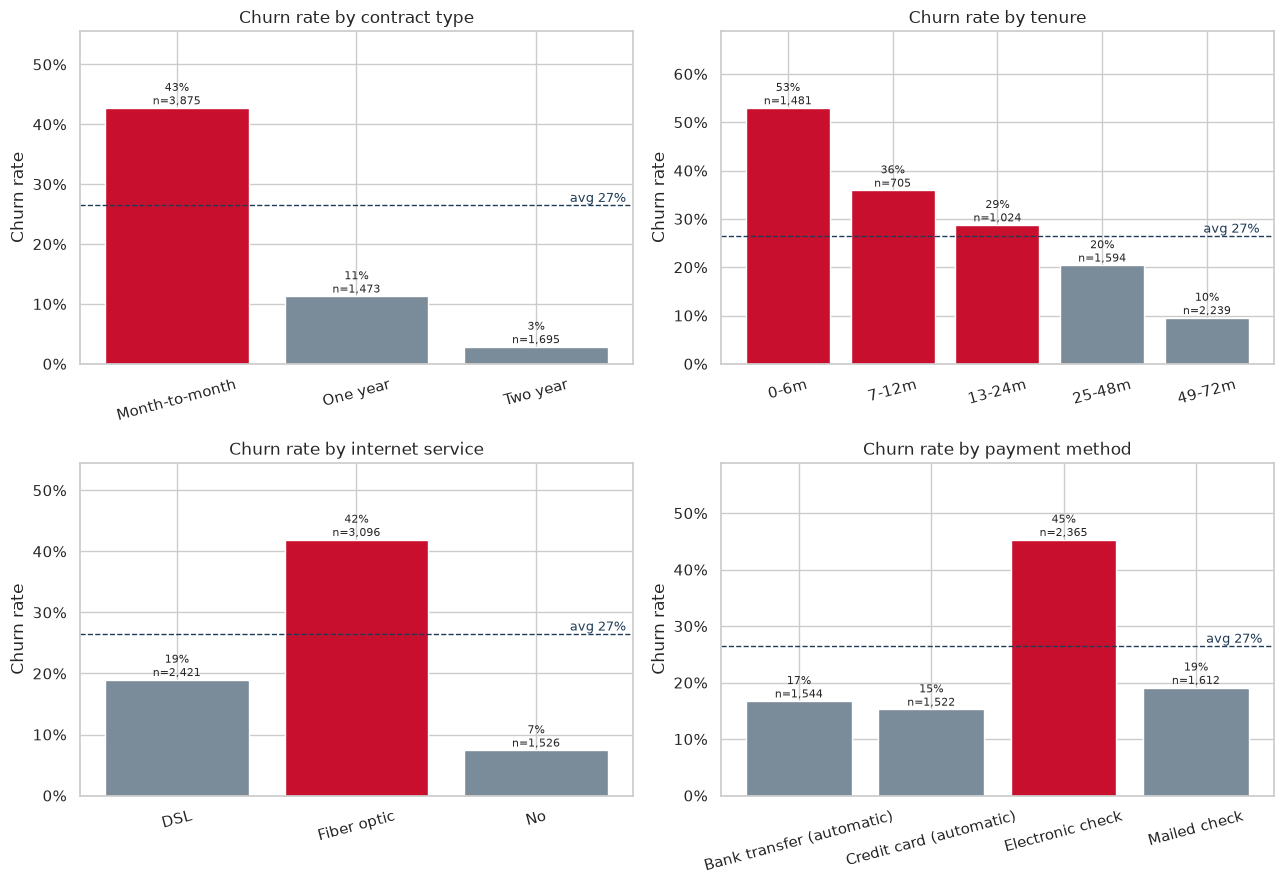

In [4]:
eda = engineer_features(df)
eda["Churned"] = eda[config.TARGET_COL].map({1: "Churned", 0: "Stayed"})
base = eda[config.TARGET_COL].mean()

def churn_rate_plot(ax, col, order=None, title=None):
    t = eda.groupby(col, observed=True)[config.TARGET_COL].agg(["mean", "size"])
    if order: t = t.reindex(order)
    bars = ax.bar(t.index.astype(str), t["mean"], color=[CHURN if v > base else STAY for v in t["mean"]])
    ax.axhline(base, ls="--", color=ACCENT, lw=1)
    ax.text(len(t) - 0.5, base, f" avg {base:.0%}", va="bottom", ha="right", color=ACCENT, fontsize=9)
    for b, (m, n) in zip(bars, t.values):
        ax.text(b.get_x() + b.get_width() / 2, m, f"{m:.0%}\nn={int(n):,}", ha="center", va="bottom", fontsize=8)
    ax.set_title(title or col); ax.set_ylabel("Churn rate"); ax.set_ylim(0, max(t["mean"]) * 1.3)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.tick_params(axis="x", rotation=15)
    return t

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
t_contract = churn_rate_plot(axes[0, 0], "Contract", title="Churn rate by contract type")
t_tenure = churn_rate_plot(axes[0, 1], "tenure_bucket", order=config.TENURE_LABELS[:-1], title="Churn rate by tenure")
t_internet = churn_rate_plot(axes[1, 0], "InternetService", title="Churn rate by internet service")
t_pay = churn_rate_plot(axes[1, 1], "PaymentMethod", title="Churn rate by payment method")
fig.tight_layout(); save(fig, "eda_churn_rates"); plt.show()

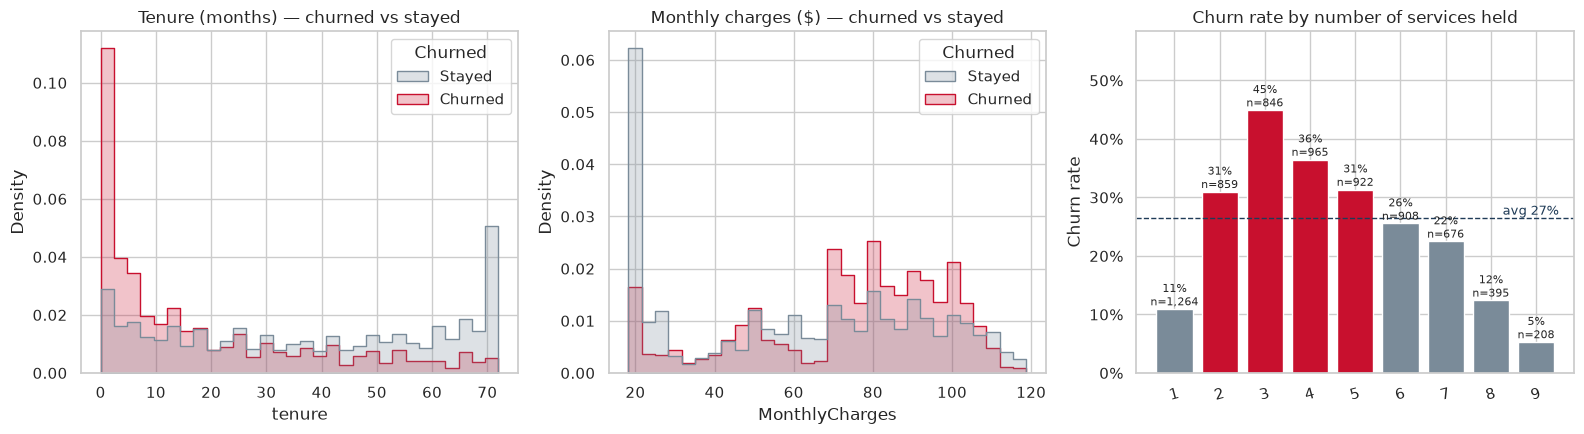

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col, title in [(axes[0], "tenure", "Tenure (months)"), (axes[1], "MonthlyCharges", "Monthly charges ($)")]:
    sns.histplot(data=eda, x=col, hue="Churned", stat="density", common_norm=False, bins=30,
                 palette={"Churned": CHURN, "Stayed": STAY}, ax=ax, element="step")
    ax.set_title(f"{title} — churned vs stayed")
churn_rate_plot(axes[2], "num_services", title="Churn rate by number of services held")
fig.tight_layout(); save(fig, "eda_distributions"); plt.show()

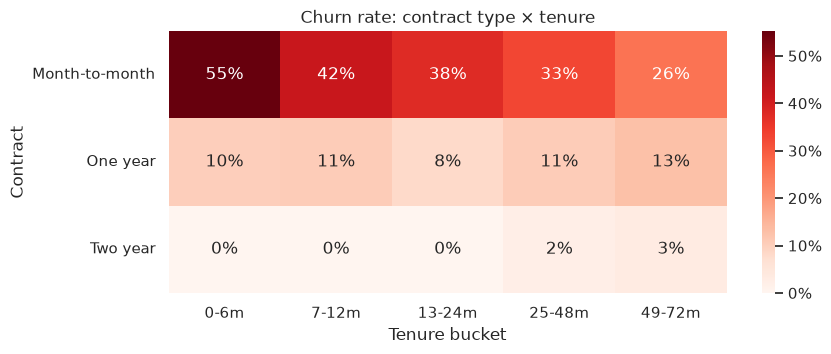

,segment,churn_rate
0,Month-to-month,42.7%
1,Two year,2.8%
2,Tenure 0-6m,52.9%
3,Fiber optic,41.9%
4,Electronic check,45.3%
5,All customers,26.5%


In [6]:
pivot = eda.pivot_table(index="Contract", columns="tenure_bucket", values=config.TARGET_COL, aggfunc="mean", observed=True)
pivot = pivot[[c for c in config.TENURE_LABELS if c in pivot.columns]]
fig, ax = plt.subplots(figsize=(9, 3.4))
sns.heatmap(pivot, annot=True, fmt=".0%", cmap="Reds", cbar_kws={"format": plt.FuncFormatter(lambda v, _: f"{v:.0%}")}, ax=ax)
ax.set_title("Churn rate: contract type × tenure"); ax.set_xlabel("Tenure bucket")
save(fig, "eda_contract_tenure_heatmap"); plt.show()

summary = pd.DataFrame({
    "segment": ["Month-to-month", "Two year", "Tenure 0-6m", "Fiber optic", "Electronic check", "All customers"],
    "churn_rate": [t_contract.loc["Month-to-month", "mean"], t_contract.loc["Two year", "mean"],
                   t_tenure.loc["0-6m", "mean"], t_internet.loc["Fiber optic", "mean"],
                   t_pay.loc["Electronic check", "mean"], base]})
summary.style.format({"churn_rate": "{:.1%}"})

**What stands out**

* **Contract type is the single strongest split.** Month-to-month customers churn at roughly 15 times the rate of two-year customers (about 43% vs 3%).
* **Churn is front-loaded.** Risk is highest in the first six months and falls steadily with tenure — the heatmap shows this holds *within* every contract type, so tenure is not just a proxy for contract.
* **Fiber optic and electronic-check customers churn more** (each around 42–45%). Fiber customers also pay the highest monthly charges (median about $92 vs $56 for DSL), so part of this may be price. Electronic check is the only manual electronic method; customers on automatic payment churn far less.
* **Service count is not linear.** Customers with a single service — mostly phone-only — rarely churn, and churn peaks at three services. Among internet customers, though, churn falls steadily with every add-on, from about half of those with none to about 5% of those with all six; online security and tech support show the biggest gaps.

These are associations, not causes; the models below test which signals still matter once the others are accounted for.

## 4. Leakage review

The brief asked whether `TotalCharges` leaks the target. Two separate questions:

1. **Is it derived from the churn outcome?** No — it is cumulative billing to date, known before the churn month.
2. **Is it redundant?** Largely: it is almost exactly tenure × monthly charge (checked below). It carries little information beyond those two, so it is kept but not over-interpreted.

The more subtle issue is the *snapshot* nature of the data: for churned customers, `tenure` is measured at the point they left. In deployment we score **active** customers at their current tenure, which is the same definition, so the model is usable — but a production version should be trained on a point-in-time snapshot (features as of month *t*, label = churned in month *t+1*).

Automated guards in `tests/test_features.py`: the target and ID are never model inputs; flipping the `Churn` column leaves every score unchanged; no single numeric feature or category level predicts churn with AUC ≥ 0.95; and a model trained on shuffled labels scores at chance. These guard against obvious target contamination. They cannot prove that every feature was available at prediction time; that needs event timestamps this dataset doesn't have.

In [7]:
approx = df["tenure"] * df["MonthlyCharges"]
r = np.corrcoef(df["TotalCharges"], approx)[0, 1]
print(f"Correlation of TotalCharges with tenure × MonthlyCharges: {r:.4f}")
from sklearn.metrics import roc_auc_score
single = {c: roc_auc_score(df[config.TARGET_COL], eda[c]) for c in ["tenure", "MonthlyCharges", "TotalCharges", "avg_monthly_charge", "charge_delta", "num_services"]}
pd.Series({k: max(v, 1 - v) for k, v in single.items()}, name="single-feature AUC").round(3).to_frame()

Correlation of TotalCharges with tenure × MonthlyCharges: 0.9996


,single-feature AUC
tenure,0.740
MonthlyCharges,0.621
TotalCharges,0.650
avg_monthly_charge,0.621
charge_delta,0.503
num_services,0.503


## 5–7. Models

`train_all` runs the full protocol:

* **80/20 stratified split.** The 20% test set (1,409 customers) is scored once at the end.
* **5-fold stratified cross-validation inside the training set** for every decision: XGBoost hyper-parameters (grid search, ROC-AUC), the decision threshold, and which model ships.
* **Decision threshold = highest cut-off that still catches ≥ 80% of churners** on out-of-fold training predictions. The retention team's priority is not missing churners (recall); the threshold is set where that target is met with as few offers as possible. It is a single setting in `config.py`.

Three models, from most to least interpretable: a depth-4 decision tree (baseline), logistic regression on the engineered features, and tuned XGBoost.

In [8]:
run = train_all(source="warehouse", save_path=None, track=False)
R = run.results
for name, r in R.items():
    print(f"{name:20s} CV ROC-AUC {r.cv_auc_mean:.4f} ± {r.cv_auc_std:.4f}   threshold {r.threshold:.3f}   {r.best_params or ''}")
print("\nSelected (best CV AUC):", run.best_name)

decision_tree        CV ROC-AUC 0.8289 ± 0.0157   threshold 0.262   
logistic_regression  CV ROC-AUC 0.8474 ± 0.0156   threshold 0.265   
xgboost              CV ROC-AUC 0.8497 ± 0.0155   threshold 0.274   {'colsample_bytree': 0.8, 'learning_rate': 0.1, 'max_depth': 1, 'min_child_weight': 10, 'n_estimators': 200, 'subsample': 0.8}

Selected (best CV AUC): xgboost


### 5. Baseline — decision tree

The value of the baseline is that it reads as plain rules. Each row below is one leaf of the depth-4 tree: the conditions that lead to it (in original units), how many training customers land there, and their actual churn rate.

In [9]:
pd.set_option("display.max_colwidth", 200)
rules = explain.leaf_rules(R["decision_tree"].pipeline, run.X_train, run.y_train)
rules.style.format({"churn_rate": "{:.1%}"}).bar(subset=["churn_rate"], color="#f4b6be", vmin=0, vmax=1)

,rule,customers,churn_rate
0,Contract is Month-to-month AND InternetService is Fiber optic AND tenure <= 15.5 AND TotalCharges <= 120.0,197,85.8%
1,Contract is Month-to-month AND InternetService is Fiber optic AND tenure <= 15.5 AND TotalCharges > 120.0,631,63.7%
2,Contract is Month-to-month AND InternetService is not Fiber optic AND tenure <= 5.5 AND TechSupport is No,294,55.1%
3,Contract is Month-to-month AND InternetService is Fiber optic AND tenure > 15.5 AND PaymentMethod is Electronic check,483,49.9%
4,Contract is Month-to-month AND InternetService is Fiber optic AND tenure > 15.5 AND PaymentMethod is not Electronic check,407,30.2%
5,Contract is Month-to-month AND InternetService is not Fiber optic AND tenure <= 5.5 AND TechSupport is not No,297,29.3%
6,Contract is Month-to-month AND InternetService is not Fiber optic AND tenure > 5.5 AND MultipleLines is No phone service,179,28.5%
7,Contract is not Month-to-month AND MonthlyCharges > 93.7 AND Contract is One year AND PaymentMethod is Electronic check,113,28.3%
8,Contract is not Month-to-month AND MonthlyCharges > 93.7 AND Contract is One year AND PaymentMethod is not Electronic check,203,17.2%
9,Contract is Month-to-month AND InternetService is not Fiber optic AND tenure > 5.5 AND MultipleLines is not No phone service,607,15.0%


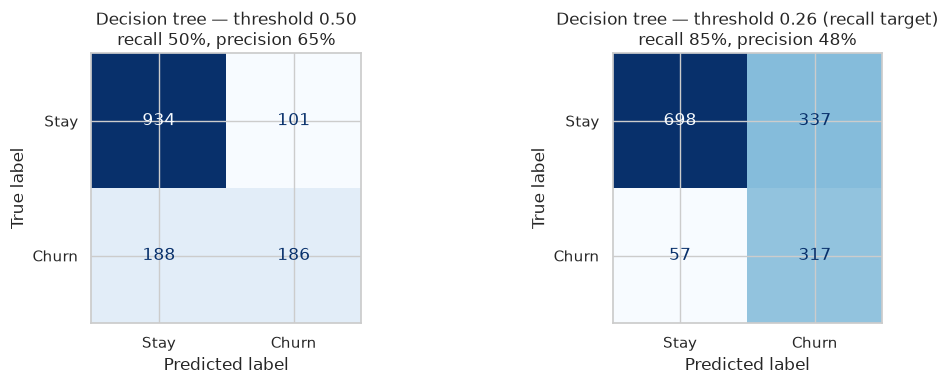

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (lbl, m) in zip(axes, [("threshold 0.50", R["decision_tree"].test_metrics_at_05), (f"threshold {R['decision_tree'].threshold:.2f} (recall target)", R["decision_tree"].test_metrics)]):
    ConfusionMatrixDisplay(np.array([[m["tn"], m["fp"]], [m["fn"], m["tp"]]]), display_labels=["Stay", "Churn"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"Decision tree — {lbl}\nrecall {m['recall']:.0%}, precision {m['precision']:.0%}")
fig.tight_layout(); save(fig, "tree_confusion"); plt.show()

The tree splits first on contract type, then (for month-to-month customers) on fiber-optic internet, then on tenure — the same story as the EDA, written as rules a retention agent could apply by hand. The riskiest leaves are month-to-month fiber customers with tenure of about 15 months or less — especially the brand-new ones who have been billed $120 or less in total. At the default 0.5 cut-off it misses about half of churners; moving the threshold to meet the recall target catches far more of them at the cost of more false alarms. **That trade-off — not accuracy — is the real decision for the retention team**, and the next section looks at it directly.

### 6. Feature engineering + logistic regression

Engineered features: average monthly charge, `charge_delta` (current charge minus lifetime average — a price-rise signal), number of services, auto-pay flag and tenure buckets.

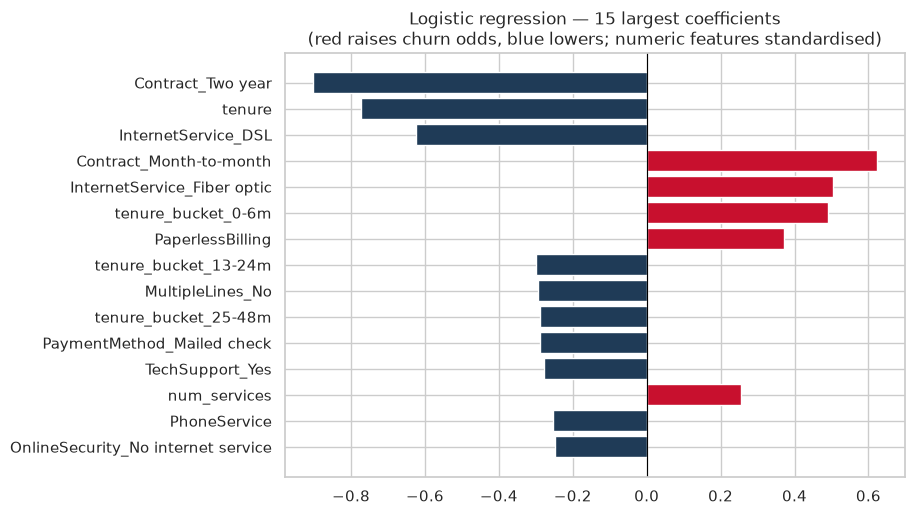

In [11]:
coefs = explain.logistic_coefficients(R["logistic_regression"].pipeline).head(15)
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(coefs["feature"][::-1], coefs["coefficient"][::-1], color=[CHURN if c > 0 else ACCENT for c in coefs["coefficient"][::-1]])
ax.axvline(0, color="black", lw=0.8); ax.set_title("Logistic regression — 15 largest coefficients\n(red raises churn odds, blue lowers; numeric features standardised)")
save(fig, "logreg_coefficients"); plt.show()

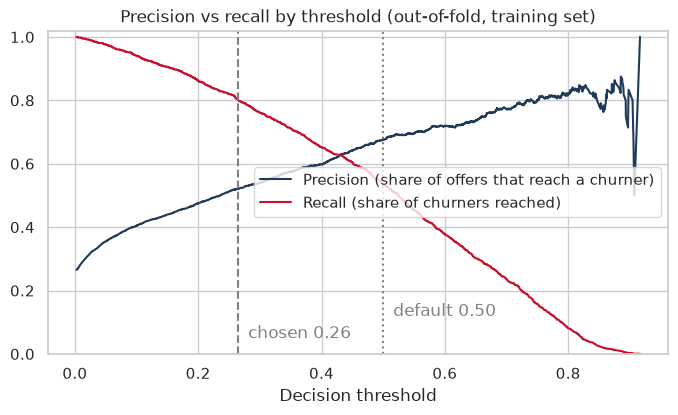

In [12]:
r = R["logistic_regression"]
p, rc, th = precision_recall_curve(run.y_train, r.oof_prob)
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(th, p[:-1], label="Precision (share of offers that reach a churner)", color=ACCENT)
ax.plot(th, rc[:-1], label="Recall (share of churners reached)", color=CHURN)
ax.axvline(r.threshold, ls="--", color="grey"); ax.text(r.threshold, 0.05, f"  chosen {r.threshold:.2f}", color="grey")
ax.axvline(0.5, ls=":", color="grey"); ax.text(0.5, 0.12, "  default 0.50", color="grey")
ax.set_xlabel("Decision threshold"); ax.set_ylim(0, 1.02); ax.legend(loc="center right")
ax.set_title("Precision vs recall by threshold (out-of-fold, training set)")
save(fig, "threshold_tradeoff"); plt.show()

Lowering the threshold trades precision for recall. Choosing where to sit on this curve is a business call: if a retention offer is cheap relative to the value of a saved customer, err toward recall (the current setting); if offers are expensive, raise the threshold. **No cost figures were provided, so none are assumed here** — once the team supplies an offer cost and a customer value, the threshold can be set to maximise expected net value instead.

### 7. Advanced model — tuned XGBoost

In [13]:
print("Best parameters:", R["xgboost"].best_params)

Best parameters: {'colsample_bytree': 0.8, 'learning_rate': 0.1, 'max_depth': 1, 'min_child_weight': 10, 'n_estimators': 200, 'subsample': 0.8}


Grid search picked **depth-1 trees ("stumps")** — each tree looks at a single feature. An initial grid already chose its shallowest corner, so it was widened in that direction and the choice held. Shallow boosting behaves like an additive model, which is a useful finding in itself: churn risk here is mostly a *sum* of independent factors (contract + tenure + service + payment) with few strong interactions. That is also why logistic regression keeps up so well.

## 8. Model comparison (held-out test set)

In [14]:
table = comparison_table(R)
table.set_index("model")[["cv_roc_auc", "cv_roc_auc_std", "test_roc_auc", "test_pr_auc", "threshold", "test_recall",
                          "test_precision", "test_f1", "test_accuracy", "accuracy_at_0.5", "recall_at_0.5", "top10_lift"]]

,cv_roc_auc,cv_roc_auc_std,test_roc_auc,test_pr_auc,threshold,test_recall,test_precision,test_f1,test_accuracy,accuracy_at_0.5,recall_at_0.5,top10_lift
model,,,,,,,,,,,,
decision_tree,0.8289,0.0157,0.8380,0.6132,0.2617,0.8476,0.4847,0.6167,0.7204,0.7949,0.4973,2.752
logistic_regression,0.8474,0.0156,0.8459,0.6643,0.2649,0.8075,0.5198,0.6325,0.7509,0.7977,0.5000,2.886
xgboost,0.8497,0.0155,0.8502,0.6732,0.2739,0.8048,0.5190,0.6310,0.7502,0.8006,0.5267,2.859


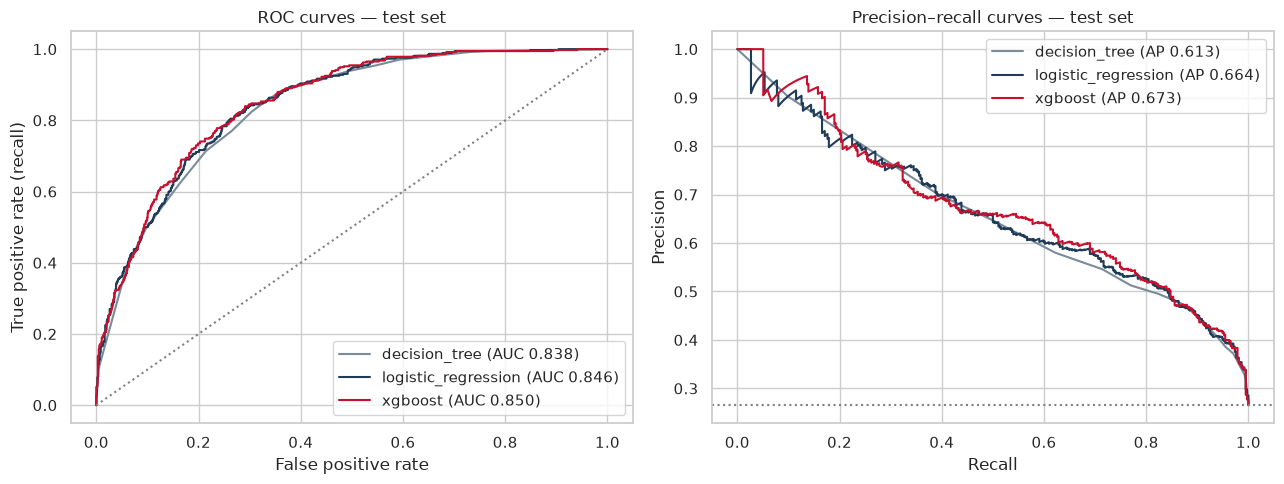

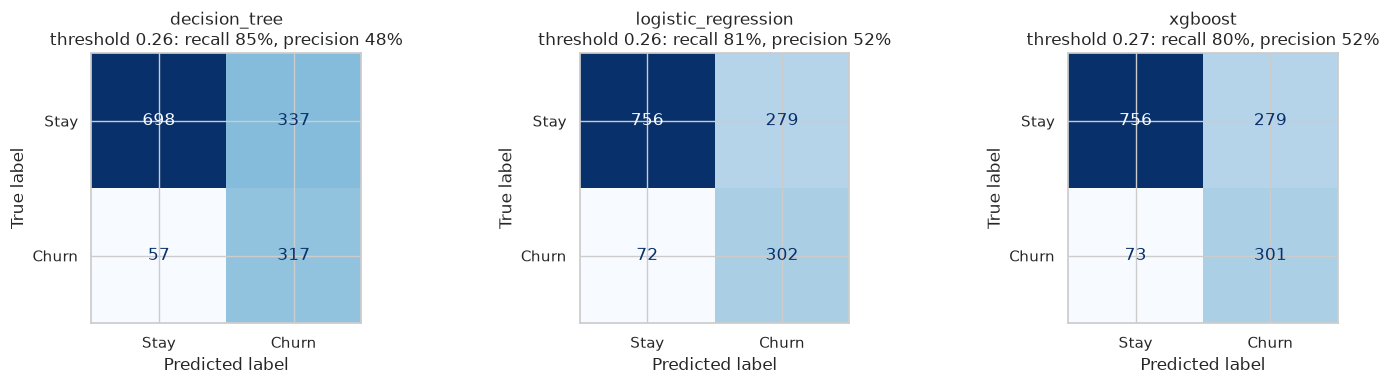

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
colors = {"decision_tree": STAY, "logistic_regression": ACCENT, "xgboost": CHURN}
for name, r in R.items():   # drawn manually so it works across scikit-learn versions
    fpr, tpr, _ = roc_curve(run.y_test, r.test_prob)
    pr, rc, _ = precision_recall_curve(run.y_test, r.test_prob)
    axes[0].plot(fpr, tpr, color=colors[name], label=f"{name} (AUC {r.test_metrics['roc_auc']:.3f})")
    axes[1].plot(rc, pr, color=colors[name], label=f"{name} (AP {r.test_metrics['pr_auc']:.3f})")
axes[0].plot([0, 1], [0, 1], ls=":", color="grey"); axes[0].set_title("ROC curves — test set")
axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate (recall)"); axes[0].legend(loc="lower right")
axes[1].axhline(run.y_test.mean(), ls=":", color="grey"); axes[1].set_title("Precision–recall curves — test set")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision"); axes[1].legend(loc="upper right")
fig.tight_layout(); save(fig, "roc_pr_curves"); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, r) in zip(axes, R.items()):
    m = r.test_metrics
    ConfusionMatrixDisplay(np.array([[m["tn"], m["fp"]], [m["fn"], m["tp"]]]), display_labels=["Stay", "Churn"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{name}\nthreshold {r.threshold:.2f}: recall {m['recall']:.0%}, precision {m['precision']:.0%}")
fig.tight_layout(); save(fig, "confusion_matrices"); plt.show()

In [16]:
dt, lr, xg = (R[k].test_metrics for k in ["decision_tree", "logistic_regression", "xgboost"])
print(f"Test ROC-AUC: tree {dt['roc_auc']:.3f} -> logistic {lr['roc_auc']:.3f} -> XGBoost {xg['roc_auc']:.3f}")
print(f"Test ROC-AUC difference, XGBoost vs tree baseline: +{xg['roc_auc'] - dt['roc_auc']:.3f}")
print(f"Test ROC-AUC difference, XGBoost vs logistic:      +{xg['roc_auc'] - lr['roc_auc']:.3f}  (CV std ≈ {R['xgboost'].cv_auc_std:.3f})")
print(f"Precision at each model's ~80%-recall threshold: tree {dt['precision']:.1%}, logistic {lr['precision']:.1%}, XGBoost {xg['precision']:.1%}")
print(f"Customers flagged on the test set: tree {dt['customers_flagged']} (catching {dt['tp']}), logistic {lr['customers_flagged']} (catching {lr['tp']}), XGBoost {xg['customers_flagged']} (catching {xg['tp']})")
from churn_pipeline.evaluation import paired_bootstrap_auc_diff
for a, b in [("xgboost", "logistic_regression"), ("xgboost", "decision_tree")]:
    bs = paired_bootstrap_auc_diff(run.y_test, R[a].test_prob, R[b].test_prob)
    print(f"Paired bootstrap, test AUC {a} - {b}: {bs['observed_diff']:+.4f}, 95% CI [{bs['ci95_low']:+.4f}, {bs['ci95_high']:+.4f}]")

Test ROC-AUC: tree 0.838 -> logistic 0.846 -> XGBoost 0.850
Test ROC-AUC difference, XGBoost vs tree baseline: +0.012
Test ROC-AUC difference, XGBoost vs logistic:      +0.004  (CV std ≈ 0.015)
Precision at each model's ~80%-recall threshold: tree 48.5%, logistic 52.0%, XGBoost 51.9%
Customers flagged on the test set: tree 654 (catching 317), logistic 581 (catching 302), XGBoost 580 (catching 301)


Paired bootstrap, test AUC xgboost - logistic_regression: +0.0043, 95% CI [-0.0002, +0.0083]


Paired bootstrap, test AUC xgboost - decision_tree: +0.0121, 95% CI [+0.0028, +0.0218]


**Reading the comparison**

* Both stronger models beat the tree baseline on ranking quality (ROC-AUC and PR-AUC); for XGBoost vs the tree, the paired bootstrap interval excludes zero. At their chosen thresholds the tree flags more customers and catches slightly more churners, so flag counts alone are not a like-for-like comparison — PR-AUC and precision are the cleaner measures.
* **The XGBoost vs logistic-regression gap is small and not clearly separable on this test set.** The paired bootstrap interval for the AUC difference just includes zero. That is not proof the models are equivalent; it means this data cannot tell them apart with confidence. XGBoost ships because the rule fixed in advance was "best cross-validated AUC"; logistic regression is a defensible alternative if directly readable coefficients matter more.
* **Accuracy is a misleading headline here.** At the default 0.5 threshold all three models score roughly 80% accuracy while missing about half of churners. At the recall-driven threshold accuracy drops, but the models catch about four in five churners — which is the actual goal.

### 8b. Are the probabilities trustworthy? Calibration and subgroups

The API's risk tiers use the probability itself ("high" means ≥ 50%), so scores should mean what they say. Below: predicted vs observed churn by score band on the test set, Brier score, and expected calibration error (ECE). Then recall and precision by the two sensitive attributes among the inputs, gender and senior-citizen status.

Brier score 0.1336 (constant-rate guess: 0.1950);  ECE 0.0207


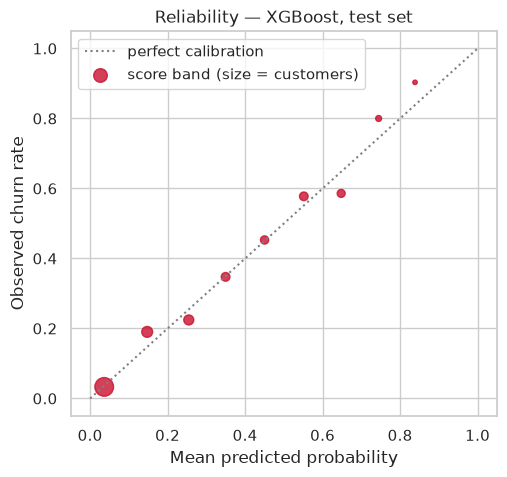

,band,customers,mean_predicted,observed_rate,gap
0,"(-0.001, 0.1]",544,0.036,0.033,-0.003
1,"(0.1, 0.2]",184,0.147,0.190,0.043
2,"(0.2, 0.3]",156,0.255,0.224,-0.030
3,"(0.3, 0.4]",118,0.350,0.347,-0.002
4,"(0.4, 0.5]",106,0.450,0.453,0.003
5,"(0.5, 0.6]",116,0.551,0.578,0.026
6,"(0.6, 0.7]",99,0.648,0.586,-0.062
7,"(0.7, 0.8]",55,0.745,0.800,0.055
8,"(0.8, 1.0]",31,0.838,0.903,0.065


In [17]:
from churn_pipeline.evaluation import calibration_table, expected_calibration_error, subgroup_metrics
best = R[run.best_name]
cal = calibration_table(run.y_test, best.test_prob)
brier_const = float(((run.y_test - run.y_train.mean()) ** 2).mean())
print(f"Brier score {best.test_metrics['brier']:.4f} (constant-rate guess: {brier_const:.4f});  ECE {expected_calibration_error(run.y_test, best.test_prob):.4f}")
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot([0, 1], [0, 1], ls=":", color="grey", label="perfect calibration")
ax.scatter(cal["mean_predicted"], cal["observed_rate"], s=cal["customers"] / 3, color=CHURN, alpha=0.8, label="score band (size = customers)")
ax.set_xlabel("Mean predicted probability"); ax.set_ylabel("Observed churn rate"); ax.legend(loc="upper left")
ax.set_title("Reliability — XGBoost, test set"); save(fig, "calibration"); plt.show()
cal.round(3)

In [18]:
groups = {"gender": run.X_test["gender"], "senior_citizen": run.X_test["SeniorCitizen"].map({0: "No", 1: "Yes"})}
pd.concat(subgroup_metrics(run.y_test, best.test_prob, g, best.threshold).assign(attribute=a) for a, g in groups.items()).set_index(["attribute", "group"]).round(3)

customers  actual_churn_rate  flag_rate  recall  \
attribute      group                                                     
gender         Female        716              0.257      0.409   0.810   
               Male          693              0.274      0.414   0.800   
senior_citizen No           1175              0.237      0.369   0.771   
               Yes           234              0.406      0.624   0.905   

                       precision  roc_auc  
attribute      group                       
gender         Female      0.509    0.849  
               Male        0.530    0.852  
senior_citizen No          0.495    0.850  
               Yes         0.589    0.827

**Calibration** is good: band-level gaps are small relative to band sizes, and ECE is about two percentage points, so recalibration is not warranted. The probabilities can be read at face value on this data.

**Subgroups.** Results for men and women are close. Senior citizens are flagged far more often, which tracks their much higher actual churn rate in this sample; their ranking quality is a little lower, and the group is small (234 test customers). Whether gender and age should be model inputs at all is a policy and legal question for the client, not a modelling one — see `LIMITATIONS_AND_PRODUCTION_PLAN.md`.

## 9. What drives churn — SHAP (XGBoost)

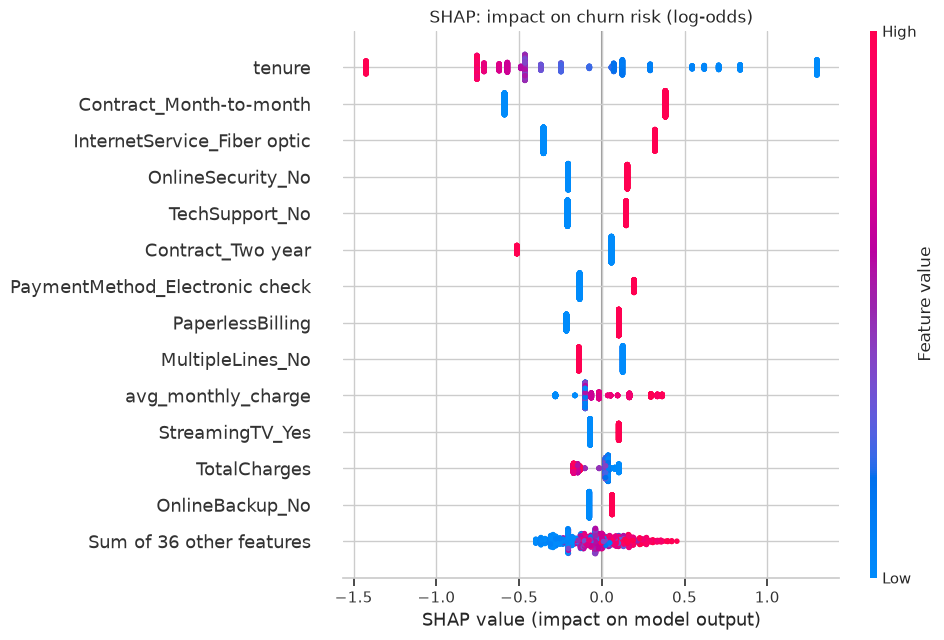

,feature,mean_abs_shap
0,tenure,0.6240
1,Contract_Month-to-month,0.4767
2,InternetService_Fiber optic,0.3384
3,OnlineSecurity_No,0.1796
4,TechSupport_No,0.1782
5,Contract_Two year,0.1661
6,PaymentMethod_Electronic check,0.1540
7,PaperlessBilling,0.1458
8,MultipleLines_No,0.1324
9,avg_monthly_charge,0.1296


In [19]:
sv = explain.shap_values(R["xgboost"].pipeline, run.X_train, max_rows=1500)
import shap
plt.figure(); shap.plots.beeswarm(sv, max_display=14, show=False)
plt.title("SHAP: impact on churn risk (log-odds)"); save(plt.gcf(), "shap_beeswarm"); plt.show()
explain.shap_importance(sv).head(10).round(4)

How to read it: each dot is a customer; dots to the right push the prediction toward churn. Colour shows the feature's value (red = high).

Consistent with the EDA and the logistic coefficients, the top drivers are **month-to-month contracts, short tenure, fiber-optic internet, the absence of online security / tech support, and electronic-check payment**. High tenure and two-year contracts pull risk down strongly. These map directly to interventions the retention team can test: contract-upgrade offers for early-tenure month-to-month customers, bundling security/tech support for fiber customers, and moving electronic-check payers to auto-pay.

## 10. Business view — who to target

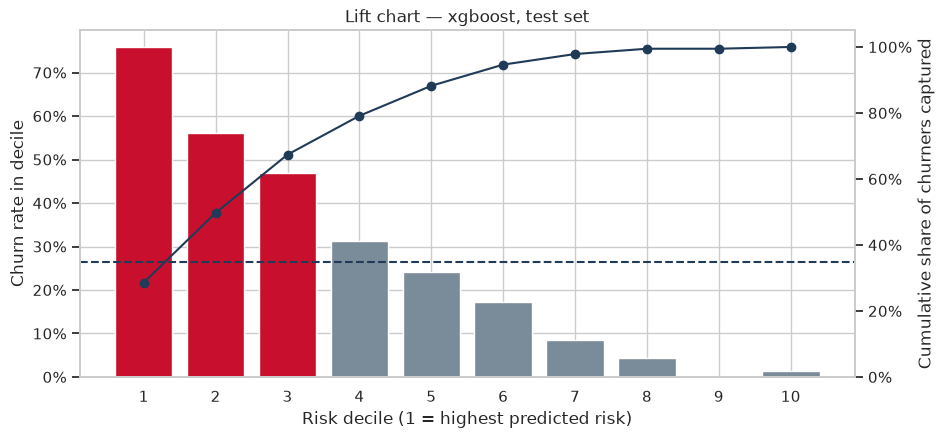

,decile,customers,churners,avg_score,churn_rate,lift,cum_capture
0,1,141,107,0.736,75.9%,2.86,28.6%
1,2,141,79,0.579,56.0%,2.11,49.7%
2,3,141,66,0.452,46.8%,1.76,67.4%
3,4,141,44,0.328,31.2%,1.18,79.1%
4,5,141,34,0.234,24.1%,0.91,88.2%
5,6,140,24,0.146,17.1%,0.65,94.7%
6,7,141,12,0.082,8.5%,0.32,97.9%
7,8,141,6,0.041,4.3%,0.16,99.5%
8,9,141,0,0.021,0.0%,0.00,99.5%
9,10,141,2,0.011,1.4%,0.05,100.0%


In [20]:
best = R[run.best_name]
dec = decile_table(run.y_test, best.test_prob)
fig, ax1 = plt.subplots(figsize=(10, 4.5))
ax1.bar(dec["decile"].astype(str), dec["churn_rate"], color=[CHURN if i < 3 else STAY for i in range(10)])
ax1.axhline(run.y_test.mean(), ls="--", color=ACCENT); ax1.set_ylabel("Churn rate in decile")
ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax2 = ax1.twinx(); ax2.plot(dec["decile"].astype(str), dec["cum_capture"], marker="o", color=ACCENT)
ax2.set_ylabel("Cumulative share of churners captured"); ax2.set_ylim(0, 1.05); ax2.grid(False)
ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax1.set_xlabel("Risk decile (1 = highest predicted risk)"); ax1.set_title(f"Lift chart — {run.best_name}, test set")
save(fig, "lift_chart"); plt.show()
dec.style.format({"avg_score": "{:.3f}", "churn_rate": "{:.1%}", "lift": "{:.2f}", "cum_capture": "{:.1%}"})

In [21]:
m = best.test_metrics
top3 = dec.loc[2, "cum_capture"]
print(f"Test set: {len(run.y_test):,} customers, {int(run.y_test.sum())} churners ({run.y_test.mean():.1%}).")
print(f"Top 10% by risk: churn rate {m['top10_churn_rate']:.1%} = {m['top10_lift']:.2f}x the average; captures {m['top10_capture']:.1%} of churners.")
print(f"Top 30% by risk captures {top3:.1%} of churners.")
print(f"At the operating threshold ({best.threshold:.3f}): {m['customers_flagged']} customers flagged, {m['tp']} of them churned "
      f"(precision {m['precision']:.1%}), {m['churners_missed']} churners not flagged (recall {m['recall']:.1%}).")

Test set: 1,409 customers, 374 churners (26.5%).
Top 10% by risk: churn rate 75.9% = 2.86x the average; captures 28.6% of churners.
Top 30% by risk captures 67.4% of churners.
At the operating threshold (0.274): 580 customers flagged, 301 of them churned (precision 51.9%), 73 churners not flagged (recall 80.5%).


Two ways to use the scores:

* **Fixed budget:** if the team can only contact *N* customers a month, take the top *N* by probability — the lift chart shows what share of churners that reaches.
* **Fixed coverage:** if the goal is to reach a target share of churners, use the operating threshold (the API's `churn_flag`). Expect roughly one in two flagged customers to be a true churner at the current setting.

The top-*N* rankings and the threshold flags describe different targeting policies, so their figures are not directly comparable.

Setting expectations: a flag is a probability, not a certainty. About half of flagged customers would not have left anyway, and roughly one in five churners will not be flagged. The evaluation is on historical data; actual intervention impact should be measured with a holdout (control) group when offers go out.

## 11. Serving and monitoring demo (local)

In [22]:
from churn_pipeline.predict import ChurnPredictor
pred = ChurnPredictor(config.MODEL_PATH, log_path=None)
print("Packaged model:", pred.model_version, "| threshold", round(pred.threshold, 4))
new = pd.read_csv(config.DATA_DIR / "sample" / "new_customers.csv", dtype={"TotalCharges": str})
pred.predict(new, log=False).merge(new[[config.ID_COL, "Contract", "tenure", "InternetService", "PaymentMethod", "MonthlyCharges"]]).sort_values("churn_probability", ascending=False)

Packaged model: xgboost-202611131338-16320c9c | threshold 0.2739


,customerID,churn_probability,churn_flag,risk_tier,Contract,tenure,InternetService,PaymentMethod,MonthlyCharges
2,1976-CFOCS,0.6475,True,high,Month-to-month,1,DSL,Electronic check,46.00
0,6481-ESCNL,0.4682,True,medium,Month-to-month,29,Fiber optic,Bank transfer (automatic),100.55
7,0637-UBJRP,0.3910,True,medium,Month-to-month,13,Fiber optic,Electronic check,84.05
6,2302-ANTDP,0.3441,True,medium,Month-to-month,48,Fiber optic,Electronic check,117.45
4,6353-BRMMA,0.3363,True,medium,Month-to-month,54,Fiber optic,Bank transfer (automatic),104.10
1,6143-JQKEA,0.3072,True,medium,Month-to-month,10,DSL,Credit card (automatic),45.80
5,6122-EFVKN,0.0260,False,low,Two year,24,DSL,Mailed check,35.75
3,1074-WVEVG,0.0168,False,low,One year,59,No,Mailed check,20.35


In [23]:
import joblib
from churn_pipeline.monitoring import read_prediction_log, drift_report
log_df = read_prediction_log()
if log_df.empty:
    print("No prediction log yet — run scripts/simulate_traffic.py first.")
else:
    ref = joblib.load(config.MODEL_PATH)["reference_profile"]
    recent = log_df.tail(500)   # the simulated 'drifted' batch
    table_d, summ = drift_report(recent, ref)
    print({k: summ[k] for k in ["n_predictions", "mean_score_training", "mean_score_current", "score_psi", "features_significant"]})
    display(table_d.head(8))

{'n_predictions': 500, 'mean_score_training': 0.2655, 'mean_score_current': 0.2797, 'score_psi': 0.0355, 'features_significant': ['MonthlyCharges', 'charge_delta', 'PaymentMethod']}


,feature,type,psi,status,unseen_categories
0,charge_delta,numeric,4.9615,significant,
1,MonthlyCharges,numeric,1.0281,significant,
2,PaymentMethod,categorical,0.8163,significant,Digital wallet
3,Contract,categorical,0.0929,stable,
4,tenure,numeric,0.0274,stable,
5,avg_monthly_charge,numeric,0.0247,stable,
6,TotalCharges,numeric,0.0211,stable,
7,auto_pay,categorical,0.0154,stable,


The simulated "next month" batch (synthetic: +15% monthly charges with cumulative `TotalCharges` left unchanged, more month-to-month contracts, a new "Digital wallet" payment method) stress-tests the monitoring; it is not a realistic price intervention, and input drift is not the same as live model accuracy, which needs the delayed churn outcomes. The log is privacy-minimised (hashed IDs, no demographic fields), so demographic features are not part of this report. Results: the price change shows up as significant PSI on `MonthlyCharges` and `charge_delta`, and the unseen payment method is flagged by name. The shift in contract mix moved PSI only to just under the 0.10 "moderate" line, a reminder that PSI cut-offs are rules of thumb and the per-feature table is worth reading, not just the flags. The model still scores those records (the unknown category is ignored by the encoder), and the API returns a warning so the issue is visible upstream.

## 12. Conclusions

1. **Who churns:** month-to-month customers in their first year, especially fiber-optic customers without security/support add-ons who pay by electronic check.
2. **Model:** tuned XGBoost (depth-1 trees) is selected; it beats the decision-tree baseline, and its edge over logistic regression is small and not clearly separable on this test set. Probabilities are well calibrated.
3. **Operating point:** the threshold is set to catch about 80% of held-out churners; roughly half of flagged customers churned. This is a configurable business choice.
4. **Prototype scope:** a locally served, container-packaged prototype on a public historical snapshot — packaged pipeline (raw CRM record in, probability out), REST API, Dockerfile, automated tests including leakage guards, a CI workflow definition, privacy-minimised prediction logging and drift reporting on synthetic traffic. These are offline prediction results; no retention offers were sent, so nothing here measures churn actually prevented.

**Next steps** (detail in `LIMITATIONS_AND_PRODUCTION_PLAN.md`): retrain and validate on point-in-time monthly snapshots; get offer cost and customer lifetime value from the business to set the threshold by expected value; run offers with a control group to measure actual saves; schedule the drift report and retrain when it flags significant shift.